# 🏦 Loan Default Prediction using Naïve Bayes



## 🔁 Workflow

```
Load Data → EDA → Preprocessing → Train/Test Split →
Train Model → Evaluate → Visualize Results
```

##  Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



##  Step 2: Load the Dataset

In [2]:
df = pd.read_csv('/content/loan_data (1).csv')
# df.shape
df.isnull().sum()
df.dropna(inplace = True)


##  Step 3: Exploratory Data Analysis (EDA)

<Axes: xlabel='loan_status', ylabel='count'>

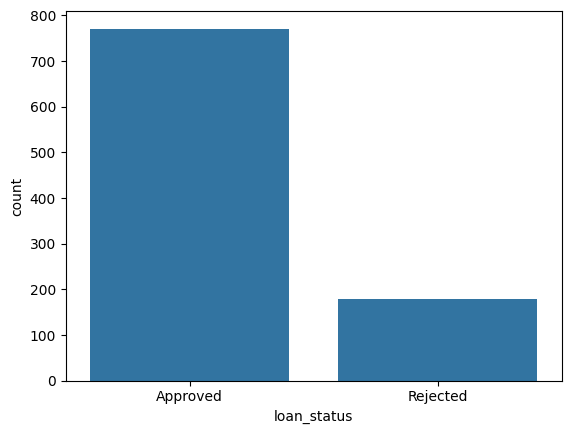

In [3]:
# Basic info
df.info
# Statistical summary
df.describe()
# Missing values
df.isnull().sum()
# Target variable distribution
df['loan_status'].value_counts()

# Correlation heatmap (numeric columns only)
sns.countplot(data = df, x ='loan_status')

## 🛠️ Step 4: Data Preprocessing

> **Why preprocessing?**  
> Naïve Bayes (GaussianNB) works with **numeric values only**.  
> We need to convert categorical columns (text) into numbers using **Label Encoding/ oneHot Encoding**.

In [4]:
df_copy = df.copy()
df_copy = df_copy.drop('applicant_id', axis = 1)

In [5]:
# Identify categorical columns
cat_col = df_copy.select_dtypes(include='object').columns.drop('loan_status')
cat_col

Index(['city', 'education', 'employment_type'], dtype='object')

In [6]:
# one hot encoding
df_copy = df.copy()
df_copy = pd.get_dummies(df_copy,
                         columns = cat_col,
                         dtype = int,
                         drop_first= True)
df_copy.head(2)
df_copy.shape

(950, 19)

In [7]:
df_copy = df_copy.drop('applicant_id', axis = 1)


In [8]:
from sklearn.preprocessing import LabelEncoder

Le = LabelEncoder()
df_copy['loan_status'] = Le.fit_transform(df_copy['loan_status'])
df_copy['loan_status'].head()

,loan_status
0,0
1,1
2,0
3,0
4,0


In [9]:
X = df_copy.drop('loan_status', axis = 1)
y = df_copy['loan_status']


In [10]:
# Define Features (X) and Target (y)

## ✂️ Step 5: Train-Test Split

> We split the data into **80% training** and **20% testing**.  
> The model **learns from training data** and is **evaluated on test data** it has never seen.

In [11]:
# Train-Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

In [12]:
# Perform class imbalance
from imblearn.over_sampling import SMOTE
sm = SMOTE(random_state=42)
X_train, y_train = sm.fit_resample(X_train, y_train)
X_train.shape, y_train.shape

((1048, 17), (1048,))

## 🤖 Step 6: Train the Naïve Bayes Model

> **GaussianNB** assumes features follow a **Normal (Gaussian) distribution**.  
> It calculates the **mean** and **variance** of each feature for each class.

In [13]:
# Initialize and Train the model
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
gnb.fit(X_train, y_train)


GaussianNB()

In [14]:
y_pred = gnb.predict(X_test)
y_pred[:10]

array([0, 0, 1, 0, 0, 1, 1, 0, 1, 1])

In [15]:
compare = pd.DataFrame({
    'Actual' : y_test,
    'Predicted' : y_pred
})
compare.head(10)

,Actual,Predicted
210,0,0
977,0,0
726,0,1
836,1,0
918,0,0
607,0,1
865,0,1
972,0,0
517,1,1
184,0,1


## 📊 Step 7: Model Evaluation

In [16]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# Predictions
y_pred = gnb.predict(X_test)

# Evaluation metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Accuracy:", accuracy)


Precision: 0.22959183673469388
Recall: 0.6716417910447762
F1 Score: 0.34220532319391633
Accuracy: 0.44904458598726116


## 🔮 Step 8: Predict for a New Loan Applicant

> Let's simulate a **real-world prediction** for a new applicant who has **not been seen by the model** before.

In [18]:
## Step 8: Predict for a New Loan Applicant
## Step 8: Predict for a New Loan Applicant

# Create a new applicant using the original/raw feature names
new_applicant = pd.DataFrame({
    'age': [30],
    'annual_income': [50000],
    'loan_amount': [200000],
    'credit_score': [750],
    'city': ['Delhi']
})

# Apply the same encoding used during training
new_applicant = pd.get_dummies(
    new_applicant,
    columns=['city'],
    drop_first=False
)

# Make sure new applicant has exactly the same columns as training data
new_applicant = new_applicant.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Make prediction
prediction = gnb.predict(new_applicant)

# Display result
if prediction[0] == 1:
    print("Loan Approved")
else:
    print("Loan Not Approved")

Loan Approved


# KNN

In [19]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

### Feature Scaling for KNN

> KNN is sensitive to the scale of the features. We need to standardize the features so that all features contribute equally to the distance calculation.

In [20]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_Scaled = scaler.transform(X_train)
X_test_Scaled = scaler.transform(X_test)
print(" Feature Scaled Successfully")



 Feature Scaled Successfully


### Train the KNN Model

> We will train a K-Nearest Neighbors classifier on the scaled training data.

In [21]:
# Initialize KNN classifier with n_neighbors (e.g., 5)
neigh = KNeighborsClassifier(n_neighbors=3)
neigh.fit(X_train_Scaled, y_train)
print("KNN Trained Successfully")

KNN Trained Successfully


### Make Predictions with KNN

In [22]:
y_predict = neigh.predict(X_test_Scaled)
y_predict[:10]

array([0, 1, 0, 0, 0, 0, 0, 0, 0, 0])

In [23]:
compare = pd.DataFrame({
    'Actual' : y_test,
    'Predicted' : y_predict
})
compare.head(10)

,Actual,Predicted
210,0,0
977,0,1
726,0,0
836,1,0
918,0,0
607,0,0
865,0,0
972,0,0
517,1,0
184,0,0


### Evaluate the KNN Model

> We will evaluate the KNN model using a classification report and confusion matrix to understand its performance.

In [24]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       0.79      0.77      0.78       247
           1       0.22      0.24      0.23        67

    accuracy                           0.66       314
   macro avg       0.50      0.50      0.50       314
weighted avg       0.67      0.66      0.66       314



### Visualize Confusion Matrix for KNN

Text(50.72222222222221, 0.5, 'Actual')

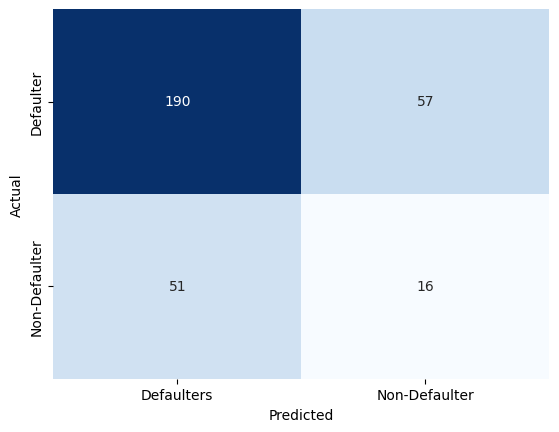

In [25]:
from sklearn.metrics import confusion_matrix
c_knn = confusion_matrix(y_test, y_predict)
sns.heatmap(c_knn, annot=True,fmt = 'd',cmap = 'Blues',cbar = False,xticklabels=['Defaulters','Non-Defaulter'],yticklabels =['Defaulter','Non-Defaulter'])
plt.xlabel('Predicted')
plt.ylabel('Actual')

### Elbow Method for Optimal K (K-Means Clustering)



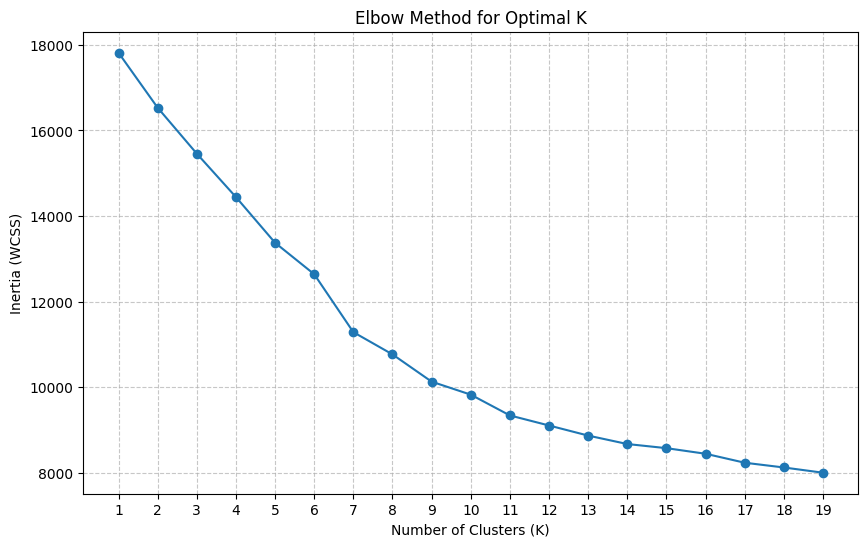

In [26]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Determine a range of K values to test
k_values = range(1, 20) # Testing from 1 to 10 clusters

inertia_values = []

for k in k_values:
    # Ensure X_train_scaled is available and contains your scaled features
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # n_init to suppress warning
    kmeans.fit(X_train_Scaled)
    inertia_values.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_values, inertia_values, marker='o', linestyle='-')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(k_values) # Ensure all k_values are shown on x-axis
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [27]:
import pickle

# Save the KNN model
with open('knn_model.pkl', 'wb') as file:
    pickle.dump(neigh, file)
print('KNN model saved as knn_model.pkl')

# Save the StandardScaler
with open('scaler.pkl', 'wb') as file:
    pickle.dump(scaler, file)
print('StandardScaler saved as scaler.pkl')

KNN model saved as knn_model.pkl
StandardScaler saved as scaler.pkl


In [28]:
import pickle

# Save the Naive Bayes model
with open('naive_bayes_model.pkl', 'wb') as file:
    pickle.dump(gnb, file)
print('Naive Bayes model saved as naive_bayes_model.pkl')

Naive Bayes model saved as naive_bayes_model.pkl


In [29]:
from google.colab import files

files.download("naive_bayes_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>